In [1]:
from langchain_groq import ChatGroq
from langchain_huggingface import HuggingFaceEmbeddings
from langgraph.graph import StateGraph,START,END
from pydantic import BaseModel,Field
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS
from langchain_tavily import TavilySearch
from typing import TypedDict,List
import os,getpass
from pprint import pprint
from dotenv import load_dotenv
load_dotenv()

True

In [2]:
embedding = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2",
 
)

llm =  ChatGroq(
        model="qwen/qwen3.8-27b", 
        temperature=0.1,
        max_tokens=512
)



In [3]:
loader = PyPDFLoader('prompt_engineering.pdf')
docs = loader.load()
print(len(docs))

splitter = RecursiveCharacterTextSplitter(chunk_size = 500,chunk_overlap=50)
chunks = splitter.split_documents(docs)
print(len(chunks))

vector_store = FAISS.from_documents(chunks,embedding=embedding)
retriever = vector_store.as_retriever(search_kwargs= {'k':4})

40
57


In [4]:
if not os.environ.get('TAVILY_API_KEY'):
    os.environ['TAVILY_API_KEY'] = getpass.getpass('Tavily API Key:\n')
    
tavily_search = TavilySearch(max_results = 1, topic='general',)


In [5]:
class evaluate(BaseModel):
    score : bool = Field(description='True when the document is relevant to the question. False otherwise')
    
grader_llm = llm.with_structured_output(evaluate)

In [6]:

class RagState(TypedDict):
    question:str
    generation:str
    web_search:bool
    documents:List[str]


def retrieve(state:RagState):
    question = state['question']  
    docs = retriever.invoke(question)
    documents = []
    
    for doc in docs:
        documents.append(doc.page_content)
        
    return {'documents':documents}




def grade_documents(state:RagState):
    
    original_documents = state['documents']
    relevant_document = []
    web_search = not original_documents
    
    
    for doc in original_documents:
        prompt = f"""Given the original question:\n {state['question']} \n and the corresponding one of the fetched document:\n {doc} \n
        . Grade it."""
        
        output  = grader_llm.invoke(prompt)
        
        if  output.score:
            relevant_document.append(doc)
        else:
            web_search = True
            
    return {'documents':relevant_document,'web_search':web_search}


def transfrom_query(state:RagState):
    prompt = f"""Given the original question:\n {state['question']} \n. Retranform this question so that we can get some meaningful
    information from the web. """
    
    output = llm.invoke(prompt).content
    
    return {'question':output}


def web_search_node(state:RagState):
    question = state['question']
    documents = state['documents']
    
    output = tavily_search.invoke(question)
    pprint(output)
    # results_list = output.get('results',[])
    # web_results = "\n".join(result['content'] for result in results_list)

    web_results = output['results'][0]['content']
    documents.append(web_results)
    
    return {'documents':documents}


def generate(state:RagState):
    question = state['question']
    context = "\n\n".join(state['question'])
    
    prompt = f"""Given the question: {state['question']} \n\n and the coressponding documents: {context}\n\n
    .Generate an answer based on the given documents context only. If the question can not be answered with the given context then simply say you don't know and you must avoid using your trained knowledge in that case."""
    
    output = llm.invoke(prompt).content
    
    return {'generation':output}


def router(state:RagState):
    web_search = state['web_search']
    if web_search:
        return 'transform_query'
    return 'generate'

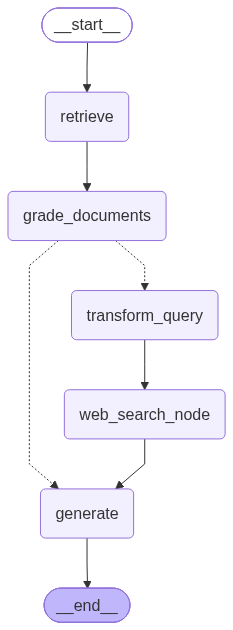

In [9]:
builder = StateGraph(RagState)

builder.add_node('retrieve',retrieve)
builder.add_node('grade_documents',grade_documents)
builder.add_node('transform_query',transfrom_query)
builder.add_node('web_search_node',web_search_node)
builder.add_node('generate',generate)

builder.add_edge(START,'retrieve')
builder.add_edge('retrieve','grade_documents')
builder.add_conditional_edges('grade_documents',router,{'transform_query':'transform_query','generate':'generate'})
builder.add_edge('transform_query','web_search_node')
builder.add_edge('web_search_node','generate')
builder.add_edge('generate',END)

graph = builder.compile()
graph

In [10]:
initial_state = {'question':'What is prompt injection?'}

final_state = graph.invoke(initial_state)
print(final_state['generation'])
    

{'answer': None,
 'follow_up_questions': None,
 'images': [],
 'query': 'To get meaningful and specific information from the web, you should '
          'transform the broad question into a more targeted query that '
          'specifies the context (e.g., AI/LLMs), the mechanism, or the '
          'implications. Here are several improved versions depending on what '
          'aspect you want to explore:\n'
          '\n'
          '### 1. For a General Technical Definition:\n'
          '> **What is prompt injection in the context of Large Language '
          'Models (LLMs), and how does it differ from traditional SQL '
          'injection?**\n'
          '\n'
          '### 2. For Understanding the Mechanism:\n'
          '> **How does prompt injection work in AI systems, and what are the '
          'common techniques used by attackers (e.g., direct vs. indirect '
          'injection)?**\n'
          '\n'
          '### 3. For Security and Mitigation:\n'
          '> **What are